In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("train.csv", encoding="latin-1")

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns)

df.head()

Dataset Shape: (27481, 10)

Column Names:
Index(['textID', 'text', 'selected_text', 'sentiment', 'Time of Tweet',
       'Age of User', 'Country', 'Population -2020', 'Land Area (Km²)',
       'Density (P/Km²)'],
      dtype='object')


,textID,text,selected_text,sentiment,Time of Tweet,Age of User,Country,Population -2020,Land Area (Km²),Density (P/Km²)
0,cb774db0d1,"I`d have responded, if I were going","I`d have responded, if I were going",neutral,morning,0-20,Afghanistan,38928346,652860.0,60
1,549e992a42,Sooo SAD I will miss you here in San Diego!!!,Sooo SAD,negative,noon,21-30,Albania,2877797,27400.0,105
2,088c60f138,my boss is bullying me...,bullying me,negative,night,31-45,Algeria,43851044,2381740.0,18
3,9642c003ef,what interview! leave me alone,leave me alone,negative,morning,46-60,Andorra,77265,470.0,164
4,358bd9e861,"Sons of ****, why couldn`t they put them on t...","Sons of ****,",negative,noon,60-70,Angola,32866272,1246700.0,26


In [4]:
print("Dataset Information:")
df.info()

print("\nSentiment Distribution:")
print(df["sentiment"].value_counts(dropna=False))

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27481 entries, 0 to 27480
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   textID            27481 non-null  object 
 1   text              27480 non-null  object 
 2   selected_text     27480 non-null  object 
 3   sentiment         27481 non-null  object 
 4   Time of Tweet     27481 non-null  object 
 5   Age of User       27481 non-null  object 
 6   Country           27481 non-null  object 
 7   Population -2020  27481 non-null  int64  
 8   Land Area (Km²)   27481 non-null  float64
 9   Density (P/Km²)   27481 non-null  int64  
dtypes: float64(1), int64(2), object(7)
memory usage: 2.1+ MB

Sentiment Distribution:
sentiment
neutral     11118
positive     8582
negative     7781
Name: count, dtype: int64

Missing Values:
textID              0
text                1
selected_text       1
sentiment           0
Time of Tweet       0
Ag

In [5]:
df = pd.read_csv(
    "train.csv",
    encoding="latin-1",
    usecols=["text", "sentiment"],
    on_bad_lines="skip"
)

df = df.dropna(subset=["text", "sentiment"])
df = df.drop_duplicates(subset=["text"])

print("Dataset Shape:", df.shape)
print("\nSentiment Distribution:")
print(df["sentiment"].value_counts())

df.head()

Dataset Shape: (27480, 2)

Sentiment Distribution:
sentiment
neutral     11117
positive     8582
negative     7781
Name: count, dtype: int64


,text,sentiment
0,"I`d have responded, if I were going",neutral
1,Sooo SAD I will miss you here in San Diego!!!,negative
2,my boss is bullying me...,negative
3,what interview! leave me alone,negative
4,"Sons of ****, why couldn`t they put them on t...",negative


In [6]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")

stop_words = set(stopwords.words("english"))

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[^a-z\s]", "", text)
    words = word_tokenize(text)
    words = [word for word in words if word not in stop_words]
    return " ".join(words)

df["clean_text"] = df["text"].apply(clean_text)

df[["text", "clean_text", "sentiment"]].head()

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\rkamb\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\rkamb\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\rkamb\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


,text,clean_text,sentiment
0,"I`d have responded, if I were going",id responded going,neutral
1,Sooo SAD I will miss you here in San Diego!!!,sooo sad miss san diego,negative
2,my boss is bullying me...,boss bullying,negative
3,what interview! leave me alone,interview leave alone,negative
4,"Sons of ****, why couldn`t they put them on t...",sons couldnt put releases already bought,negative


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)

X = tfidf.fit_transform(df["clean_text"])
y = df["sentiment"]

print("TF-IDF Matrix Shape:", X.shape)
print("Target Shape:", y.shape)

TF-IDF Matrix Shape: (27480, 5000)
Target Shape: (27480,)


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (21984, 5000)
Testing Data: (5496, 5000)


In [9]:

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

y_pred_nb = nb_model.predict(X_test)

accuracy_nb = accuracy_score(y_test, y_pred_nb)

print("Naive Bayes Model Accuracy:", accuracy_nb)
print("Accuracy Percentage:", round(accuracy_nb * 100, 2), "%")


Naive Bayes Model Accuracy: 0.6315502183406113
Accuracy Percentage: 63.16 %


In [10]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)

accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Model Accuracy:", accuracy_lr)
print("Accuracy Percentage:", round(accuracy_lr * 100, 2), "%")


Logistic Regression Model Accuracy: 0.6826783114992722
Accuracy Percentage: 68.27 %


In [11]:

from sklearn.metrics import classification_report

print("NAIVE BAYES - Evaluation")
print(classification_report(y_test, y_pred_nb))

print("\nLOGISTIC REGRESSION - Evaluation")
print(classification_report(y_test, y_pred_lr))


NAIVE BAYES - Evaluation
              precision    recall  f1-score   support

    negative       0.72      0.51      0.60      1556
     neutral       0.55      0.76      0.64      2223
    positive       0.74      0.58      0.65      1717

    accuracy                           0.63      5496
   macro avg       0.67      0.62      0.63      5496
weighted avg       0.66      0.63      0.63      5496


LOGISTIC REGRESSION - Evaluation
              precision    recall  f1-score   support

    negative       0.73      0.59      0.65      1556
     neutral       0.61      0.75      0.68      2223
    positive       0.77      0.67      0.72      1717

    accuracy                           0.68      5496
   macro avg       0.70      0.67      0.68      5496
weighted avg       0.70      0.68      0.68      5496



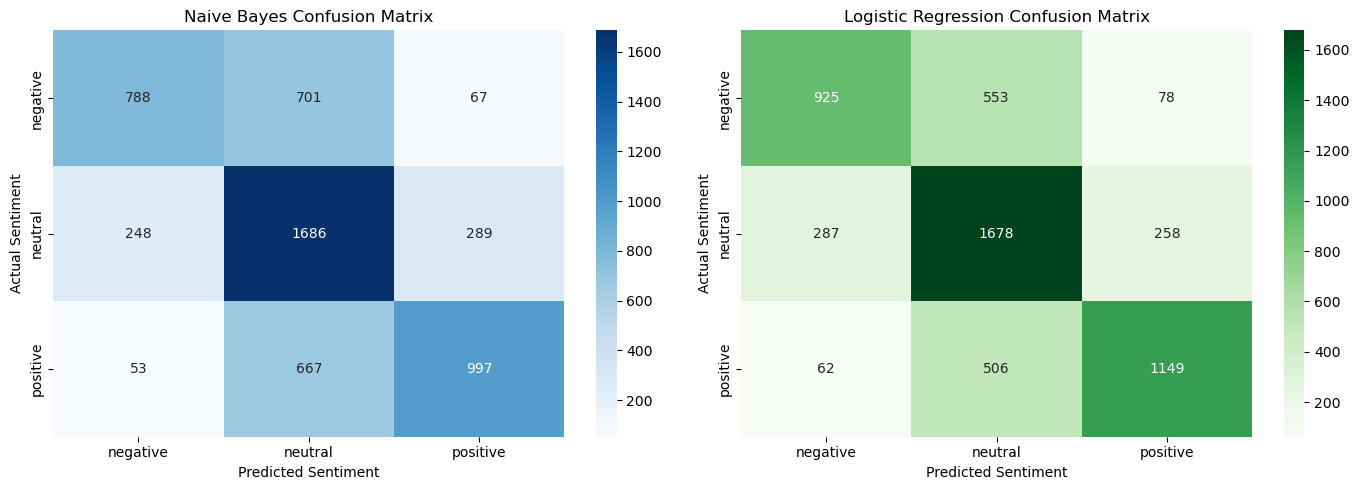

In [12]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Naive Bayes
cm_nb = confusion_matrix(
    y_test, y_pred_nb,
    labels=["negative", "neutral", "positive"]
)

sns.heatmap(
    cm_nb, annot=True, fmt="d", cmap="Blues",
    xticklabels=["negative", "neutral", "positive"],
    yticklabels=["negative", "neutral", "positive"],
    ax=axes[0]
)
axes[0].set_title("Naive Bayes Confusion Matrix")
axes[0].set_xlabel("Predicted Sentiment")
axes[0].set_ylabel("Actual Sentiment")

# Logistic Regression
cm_lr = confusion_matrix(
    y_test, y_pred_lr,
    labels=["negative", "neutral", "positive"]
)

sns.heatmap(
    cm_lr, annot=True, fmt="d", cmap="Greens",
    xticklabels=["negative", "neutral", "positive"],
    yticklabels=["negative", "neutral", "positive"],
    ax=axes[1]
)
axes[1].set_title("Logistic Regression Confusion Matrix")
axes[1].set_xlabel("Predicted Sentiment")
axes[1].set_ylabel("Actual Sentiment")

plt.tight_layout()
plt.show()


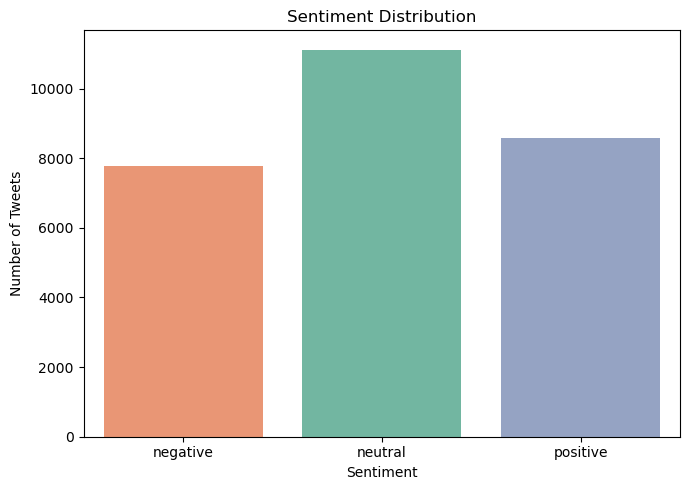

In [13]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="sentiment",
    order=["negative", "neutral", "positive"],
    hue="sentiment",
    palette="Set2",
    legend=False
)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")
plt.tight_layout()
plt.show()


In [14]:

from wordcloud import WordCloud
import matplotlib.pyplot as plt

sentiments = ["negative", "neutral", "positive"]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i, sentiment in enumerate(sentiments):
    text = " ".join(
        df.loc[df["sentiment"] == sentiment, "clean_text"]
    )

    wordcloud = WordCloud(
        width=600,
        height=400,
        background_color="white"
    ).generate(text)

    axes[i].imshow(wordcloud, interpolation="bilinear")
    axes[i].set_title(sentiment.capitalize() + " Sentiment")
    axes[i].axis("off")

plt.tight_layout()
plt.show()


ModuleNotFoundError: No module named 'wordcloud'

In [15]:

%pip install wordcloud


Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


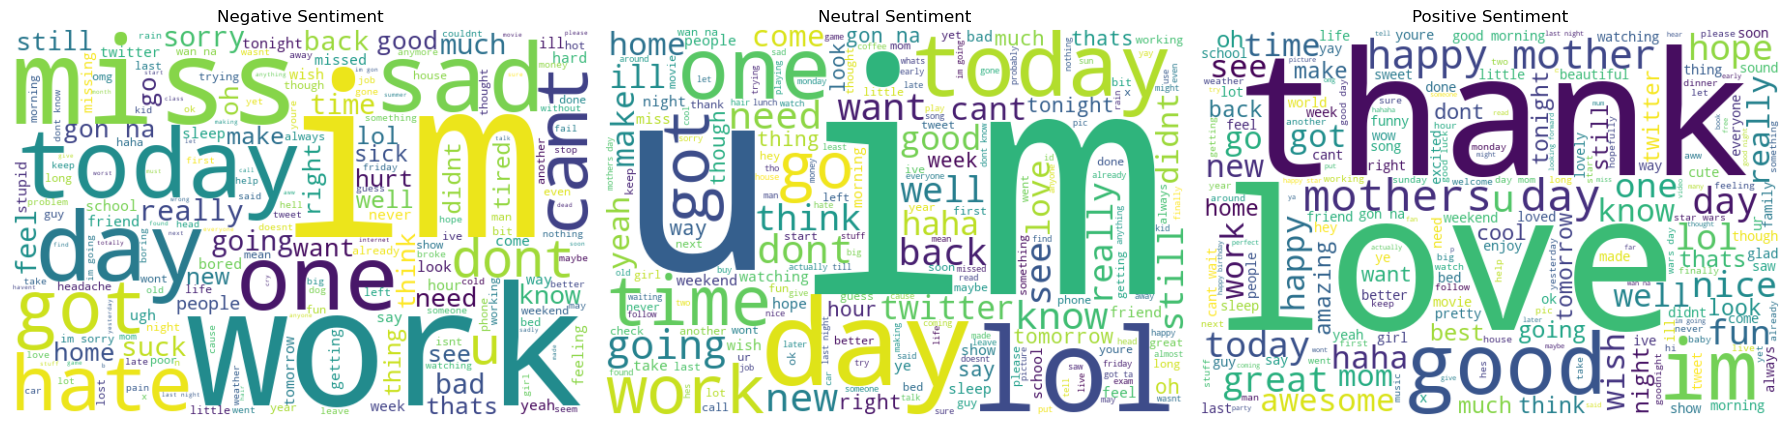

In [16]:

from wordcloud import WordCloud
import matplotlib.pyplot as plt

sentiments = ["negative", "neutral", "positive"]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i, sentiment in enumerate(sentiments):
    text = " ".join(
        df.loc[df["sentiment"] == sentiment, "clean_text"]
    )

    wordcloud = WordCloud(
        width=600,
        height=400,
        background_color="white"
    ).generate(text)

    axes[i].imshow(wordcloud, interpolation="bilinear")
    axes[i].set_title(sentiment.capitalize() + " Sentiment")
    axes[i].axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd

error_df = pd.DataFrame({
    "Actual Sentiment": y_test,
    "Predicted Sentiment": y_pred_lr
})

error_df["Text"] = df.loc[y_test.index, "text"]

misclassified = error_df[
    error_df["Actual Sentiment"] != error_df["Predicted Sentiment"]
]

misclassified = misclassified.reset_index(drop=True)

misclassified[["Text", "Actual Sentiment", "Predicted Sentiment"]].head(5)

,Text,Actual Sentiment,Predicted Sentiment
0,Hoping that this will just heal on it`s own be...,neutral,positive
1,i`m just sooo in love....i think,positive,neutral
2,yum. Do you do home delivery,positive,neutral
3,ur taking tease lessons from the guys! No fai...,neutral,positive
4,shack idol today(: can`t wait. it`s gonna be f...,neutral,negative


### Error Analysis – Misclassified Tweets

The Logistic Regression model incorrectly classified some tweets because sentiment can be difficult to identify from text alone.

1. **Actual: Neutral | Predicted: Positive**  
   Text: “Hoping that this will just heal on its own...”  
   The model may have interpreted the word “Hoping” as positive, although the tweet was labelled neutral.

2. **Actual: Positive | Predicted: Neutral**  
   Text: “I'm just sooo in love....i think”  
   The model may have failed to recognize the positive emotion expressed by the phrase “in love”.

3. **Actual: Positive | Predicted: Neutral**  
   Text: “yum. Do you do home delivery”  
   The model may not have recognized “yum” as a positive expression because the remaining text is a question.

4. **Actual: Neutral | Predicted: Positive**  
   Text: “ur taking tease lessons from the guys! No fair...”  
   The model may have interpreted the informal language and exclamation mark as positive, even though the actual label was neutral.

5. **Actual: Neutral | Predicted: Negative**  
   Text: “shack idol today(: can't wait. it's gonna be fun...”  
   The model may have misunderstood the informal writing and mixed sentiment-related words, leading to a negative prediction.

### Conclusion of Error Analysis

The errors occurred because tweets often contain informal language, abbreviations, context-dependent words, and mixed emotions. Text preprocessing may also remove useful information. These limitations can affect sentiment classification accuracy. Better preprocessing and more suitable features may improve the model's performance.

## Conclusion

In this project, sentiment analysis was performed on a dataset of tweets to classify text into negative, neutral, and positive sentiments. Text preprocessing and TF-IDF vectorization were used to prepare the data for machine learning.

Two machine learning models were trained and evaluated: Naive Bayes and Logistic Regression.

- **Naive Bayes Accuracy:** 63.16%
- **Logistic Regression Accuracy:** 68.27%

Logistic Regression performed better than Naive Bayes on this dataset. The sentiment distribution graph, WordClouds, classification reports, and confusion matrices helped analyze the results.

Sentiment analysis can be used in customer feedback analysis, social media monitoring, product reviews, and understanding public opinion. The model may still make mistakes when tweets contain informal language, abbreviations, or mixed emotions.